# EDA walkthrough: 5 business questions

**Video 6.7** | ShopKart project

**Goal:** Use the cleaned, merged ShopKart table to answer five real business questions and write the findings in plain English.

### How to open in Colab
1. Go to colab.research.google.com → **File → Upload notebook** → choose this `.ipynb` file.
2. Click the **folder icon** on the left sidebar (Files panel) and drag in the data files: `shopkart_clean.csv`.
3. Run cells one by one with **Shift + Enter**.

> Files you upload to the Files panel disappear when the runtime resets. If you see `FileNotFoundError`, upload them again.

**EDA (Exploratory Data Analysis)** = asking questions of the data, answering them with numbers (and a quick chart), and writing what it means for the business.

The ShopKart head of sales asks:
1. Which month was best for revenue?
2. Which city brings the most revenue?
3. Which category has the highest return rate?
4. Do discounts make people buy more, or rate higher?
5. Are Prime members worth it compared with Free members?

In [1]:
import pandas as pd
df = pd.read_csv("shopkart_clean.csv", parse_dates=["order_date"])
df["is_returned"] = (df["returned"] == "Y").astype(int)
print(df.shape)
print("Total revenue: ₹", round(df["revenue"].sum()))
print("Total profit: ₹", round(df["profit"].sum()))
print("Overall return rate:", round(df["is_returned"].mean() * 100, 1), "%")

(5000, 22)
Total revenue: ₹ 14704650
Total profit: ₹ 3140750
Overall return rate: 13.7 %


## Q1. Which month was best?

In [2]:
monthly = df.groupby("order_month")["revenue"].sum().round(0)
print(monthly)
print("Best month:", monthly.idxmax(), "with ₹", monthly.max())
print("Worst month:", monthly.idxmin(), "with ₹", monthly.min())

order_month
1     1073267.0
2      863480.0
3     1080122.0
4      983481.0
5      786912.0
6      793841.0
7      873632.0
8     1203393.0
9     1543639.0
10    1978317.0
11    1965664.0
12    1558902.0
Name: revenue, dtype: float64
Best month: 10 with ₹ 1978317.0
Worst month: 5 with ₹ 786912.0


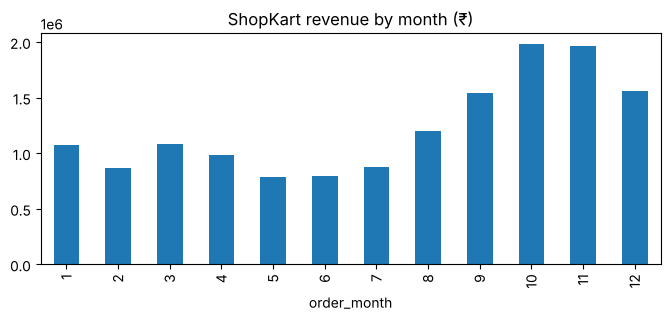

In [3]:
monthly.plot(kind="bar", title="ShopKart revenue by month (₹)", figsize=(8, 3));   # quick look - Module 8 makes it pretty

### Finding 1 - October is the best month, with November right behind
- **October** brought the most revenue: **₹19.78 lakh**. November is almost tied at **₹19.66 lakh**, and December is third (₹15.59 lakh).
- **May** was the weakest month (₹7.87 lakh), with June close behind (₹7.94 lakh). That is about 40% of October.
- October to December made about **37%** of the whole year's revenue. Revenue climbs steadily from August.

**So what:** the festive season (Navratri, Diwali, wedding season) drives the year. Stock, staff and delivery partners need to be ready from September. A May-June campaign could lift the slow middle of the year.

## Q2. Which city brings the most revenue?

In [4]:
city = df.groupby("city").agg(revenue=("revenue", "sum"), orders=("order_id", "count"),
                             avg_order=("revenue", "mean")).round(0).sort_values("revenue", ascending=False)
city["share_%"] = (city["revenue"] / city["revenue"].sum() * 100).round(1)
city

,revenue,orders,avg_order,share_%
city,,,,
Delhi,2323405.0,804,2890.0,15.8
Bengaluru,2256613.0,736,3066.0,15.3
Mumbai,2090206.0,759,2754.0,14.2
Hyderabad,1494617.0,495,3019.0,10.2
Pune,1387698.0,451,3077.0,9.4
Chennai,1333559.0,442,3017.0,9.1
Kolkata,1237204.0,414,2988.0,8.4
Ahmedabad,1065043.0,303,3515.0,7.2
Lucknow,791224.0,326,2427.0,5.4


### Finding 2 - Delhi earns the most, closely followed by Bengaluru and Mumbai
- **Delhi** is number one with **₹23.23 lakh** (15.8% of revenue, 804 orders).
- Bengaluru (₹22.57 lakh) and Mumbai (₹20.90 lakh) are close behind. These three metros make up about **45%** of revenue.
- Ahmedabad has the **highest average order** (₹3,515) but fewer orders. Lucknow has the lowest average order (₹2,427).

**So what:** the big three metros are the core market. Ahmedabad customers spend more per order, so getting more orders there could pay off.

## Q3. Which category has the highest return rate?

In [5]:
cat = df.groupby("category").agg(orders=("order_id", "count"), returns=("is_returned", "sum"),
                                return_rate=("is_returned", "mean"), revenue=("revenue", "sum")).sort_values("return_rate", ascending=False)
cat["return_rate"] = (cat["return_rate"] * 100).round(1)
cat.round(0)

,orders,returns,return_rate,revenue
category,,,,
Fashion,1326,279,21.0,3121346.0
Electronics,1152,155,14.0,7331018.0
Home,1020,127,12.0,2655047.0
Beauty,750,71,10.0,877640.0
Books,752,55,7.0,719598.0


In [6]:
# Bonus: the city outlier we spotted in 6.5
city_ret = (df.groupby("city")["is_returned"].mean() * 100).round(1).sort_values(ascending=False)
city_ret.head(3)

city
Pune         32.4
Kolkata      14.3
Ahmedabad    14.2
Name: is_returned, dtype: float64

### Finding 3 - Fashion has the highest return rate
- **Fashion: 21.0%** of orders are returned (279 of 1,326). That is well above the overall rate of **13.7%**.
- Books (7.3%) and Beauty (9.5%) are returned least.
- Bonus: **Pune** has a return rate of **32.4%**, about 2.4 times the overall rate. No other city is above 14.3%.

**So what:** Fashion returns are usually about size and fit, so better size charts and photos could help. Pune needs a separate check: delivery partner, packaging or fraud. We dig into why in Module 8 (charts) and the Module 10 capstone.

## Q4. Do discounts make people buy more, or rate higher?

In [7]:
disc = df.groupby("discount").agg(orders=("order_id", "count"), avg_quantity=("quantity", "mean"),
                                 avg_rating=("rating", "mean")).round(2)
disc

,orders,avg_quantity,avg_rating
discount,,,
0.00,1143,1.50,3.98
0.05,703,1.60,3.99
0.10,1095,1.75,3.93
0.15,767,1.89,3.99
0.20,679,1.95,3.94
0.25,156,2.29,3.78
0.30,387,2.29,3.97
0.40,70,2.53,4.00


In [8]:
print("Correlation discount vs quantity:", round(df["discount"].corr(df["quantity"]), 2))
print("Correlation discount vs rating:  ", round(df["discount"].corr(df["rating"]), 2))

Correlation discount vs quantity: 0.27
Correlation discount vs rating:   -0.01


### Finding 4 - Discounts make people buy more, but they do not make them happier
- Average quantity goes up steadily with discount: **1.50 items** with no discount, **2.53 items** at a 40% discount. Correlation = **+0.27** (a weak to moderate positive link).
- Average rating stays flat, around **3.8 to 4.0** at every discount level. Correlation = **-0.01** (no link).

**So what:** discounts work for basket size, not for satisfaction. Remember that **correlation is not causation** (Module 3): bigger discounts may simply be offered on items people buy in multiples anyway.

## Q5. Prime vs Free members

In [9]:
mem = df.groupby("membership").agg(orders=("order_id", "count"), customers=("customer_id", "nunique"),
                                   revenue=("revenue", "sum"), avg_order=("revenue", "mean"),
                                   return_rate=("is_returned", "mean")).round(2)
mem["orders_per_customer"] = (mem["orders"] / mem["customers"]).round(1)
mem["revenue_per_customer"] = (mem["revenue"] / mem["customers"]).round(0)
mem

,orders,customers,revenue,avg_order,return_rate,orders_per_customer,revenue_per_customer
membership,,,,,,,
Free,2298,482,6777859.55,2949.46,0.14,4.8,14062.0
Prime,2702,276,7926790.15,2933.68,0.13,9.8,28720.0


### Finding 5 - Prime members are worth more because they order more often, not because they spend more per order
- Average order value is almost the same: **Prime ₹2,934** vs **Free ₹2,949**.
- Each Prime customer placed **9.8 orders** in 2025, against **4.8** for each Free customer, about twice as many.
- So revenue per customer is **₹28,720 for Prime** vs **₹14,062 for Free**.
- Return rates are similar (13.2% vs 14.3%).

**So what:** Prime is a loyalty programme. Converting Free customers to Prime looks valuable, but check first: maybe loyal people join Prime, rather than Prime making people loyal (correlation vs causation again).

## One-paragraph summary for the head of sales
ShopKart made **₹1.47 crore** revenue and **₹31.4 lakh** profit from 5,000 orders in 2025. Revenue peaks in **October-November** (festive season) and is lowest in **May-June**. **Delhi, Bengaluru and Mumbai** bring about 45% of revenue. **Fashion** is returned most (21%), and **Pune** has a serious return problem (32% vs 13.7% overall). Discounts grow basket size but not ratings. **Prime** members spend the same per order as Free members but order about twice as often.

**Next:** Module 7 turns this cleaning into an automatic pipeline. Module 8 turns these findings into charts and a dashboard. Module 9 builds a model to predict which orders will be returned.